# Conjunto de treino sintético para galáxias de todos os tipos no S-PLUS

Gera modelos do Bagpipes nas 12 bandas do S-PLUS, com parâmetros sorteados por Sobol em priors amplos fixados **antes** de olhar os dados, e salva as magnitudes junto com os rótulos físicos. O redshift é livre (será uma entrada do modelo final).

**SFH (a do `simple_sampling.ipynb`).** 16 bins de idade constantes (top-hat) até a idade do Universo em $z$:
- ~46%: frações de massa Dirichlet(1) nos bins;
- ~50%: skew-normal (pico $\sim N(12, 3)$ Gyr atrás, largura $\sim N(1, 0.4)$, assimetria $U(-0.25, 0.75)$);
- ~4%: skew-normal + surto (10–500 Myr atrás, 40–50 Myr de largura, 1–10% da massa);
- enriquecimento químico: $Z$ de cada bin vai de $Z_{\rm ini}$ (população mais velha) a $Z_{\rm fin}$ conforme a massa acumulada.

Com Dirichlet(1) em 16 bins, em média ~25% da massa se forma nos últimos 100 Myr, então galáxias passivas vêm quase só do ramo skew-normal. Se a cobertura de galáxias vermelhas ficar baixa, aumente `P_SKEW`.

**Diferenças em relação ao `simple_sampling.ipynb`**
- Três correções de implementação: (1) o Bagpipes só reconhece `constant1`–`constant9` (tira um caractere do nome), então os bins 10–16, com as populações de mais de ~1 Gyr, eram descartados sem aviso; aqui os nomes são `constantA`–`constantP`. (2) `metallicity` é em $Z_\odot$, e 0.008–0.030 eram valores absolutos (≈ $0.004$–$0.015\,Z_\odot$); aqui $Z/Z_\odot$ com $Z_\odot = 0.02$. (3) O CF00 do Bagpipes ignora `mu`; a atenuação extra das nuvens de nascimento entra por `eta`.
- Priors ampliados para cobrir todos os tipos: $z$, $Z_{\rm fin}$ e $A_V$ do ISM (tabela abaixo). O resto segue o `simple_sampling.ipynb`.
- Sobol (quase-aleatório, cobre o espaço de forma mais uniforme) em vez de sorteios independentes, e sem refinamento em torno dos dados.

| parâmetro | prior |
|---|---|
| $z$ | $U(0.005, 1)$ |
| $Z_{\rm fin}$ | log-uniforme, $0.1$–$2.5\,Z_\odot$ ($Z_{\rm ini} = 0.4\,Z_{\rm fin}$) |
| $A_V$ do ISM | $U(0.01, 2)$ mag |
| $A_V$ extra das nuvens de nascimento (< 10 Myr) | $1.086\,\tau_{\rm BC}$, $\tau_{\rm BC}$ log-uniforme em 0.5–4 |
| $\log U$ | $U(-4, -1)$ |

**Saída** (`training_set.csv`): parâmetros sorteados, rótulos e as 12 magnitudes AB para $10^{10}\,M_\odot$ formados. Para uma galáxia observada, o offset $\Delta m = m_{\rm obs} - m_{\rm mod}$ escala massa e SFR: $\log M_\star = $ `log_mstar` $- 0.4\,\Delta m$ (idem para `log_sfr`). Idade, frações da SFH e poeira não dependem da normalização. O `z` é entrada do modelo final, junto com as magnitudes, não um rótulo a prever.

**Cobertura.** A última seção mede, numa amostra limpa do S-PLUS, a fração de galáxias que algum modelo reproduz com $\chi^2_\nu < 2$ num redshift compatível com o photo-z. Onde a cobertura falhar, amplie o prior correspondente e gere de novo; não acrescente modelos ajustados galáxia a galáxia.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import bagpipes as pipes
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from joblib import Parallel, delayed
from scipy.integrate import simpson
from scipy.stats import qmc, norm, skewnorm

warnings.filterwarnings("ignore", category=RuntimeWarning)

N_MODELS = 2**18          # potência de 2 (Sobol); ~6 ms por modelo e núcleo
SEED = 0
N_JOBS = 10
OUTPUT = "training_set.csv"

Z_RANGE = (0.005, 1.0)        # redshift
LOG_ZFIN = (-1.0, 0.4)        # log(Z_fin / Z_sun): 0.1 a 2.5
ZINI_FRAC = 0.4               # Z_ini = ZINI_FRAC * Z_fin (0.008 / 0.02 no simple_sampling)
AV_ISM = (0.01, 2.0)          # A_V do ISM [mag]
LOG_TAU_BC = (np.log10(0.5), np.log10(4.0))
LOGU = (-4.0, -1.0)
DUST_N = 0.7                  # expoente da lei de atenuação CF00
T_BC = 0.01                   # idade máxima das nuvens de nascimento [Gyr]
LOG_MASS = 10.0               # log da massa formada [M_sun]
P_SKEW, P_BURST = 0.5, 6 / 165   # frações de SFH skew-normal (total) e skew-normal + surto; o resto é Dirichlet
MIN_FRAC = 1e-6               # fração mínima por bin (mantém os 16 componentes no modelo)
SFR_FLOOR = 1e-14             # piso de sSFR [yr^-1] para log_sfr de SFHs sem formação recente

AGE_BINS = np.array([0.007, 0.021, 0.0425, 0.076, 0.1145, 0.1615, 0.23, 0.345,
                     0.545, 0.865, 1.37, 2.17, 3.44, 5.455, 8.645, 14.2])   # centros dos bins [Gyr]
LABEL_EDGES = [0.1, 1.0]      # rótulos da SFH: fração da massa formada em < 0.1, 0.1–1 e > 1 Gyr atrás

Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


## SFH
Cada modelo é um vetor Sobol $u \in [0, 1)^{d}$; as funções abaixo o transformam nos parâmetros físicos pelas inversas das distribuições, então as proporções da SFH (Dirichlet, skew-normal, surto) e os priors ficam exatamente os da tabela.

In [2]:
cosmo = FlatLambdaCDM(H0=70.0, Om0=0.3)
N_BINS = len(AGE_BINS)
DIMS = ["z", "sfh_type", *[f"dir{i}" for i in range(N_BINS)], "peak", "width", "skew",
        "burst_age", "burst_width", "burst_frac", "log_zfin", "av_ism", "log_tau_bc", "logU"]


def uniform(u, lo, hi):
    return lo + (hi - lo) * u


def truncnorm_pos(u, mu, sigma):
    """N(mu, sigma) truncada em > 0, pela inversa da CDF (como o laço 'while <= 0' do simple_sampling)."""
    p0 = norm.cdf(0, mu, sigma)
    return norm.ppf(p0 + u * (1 - p0), mu, sigma)


def bin_edges(z):
    """Bordas dos bins [Gyr atrás], cortadas em 0.1 Gyr antes da idade do Universo em z."""
    t_max = cosmo.age(z).value - 0.1
    centers = AGE_BINS[AGE_BINS <= t_max]
    return np.concatenate([[0.0], (centers[:-1] + centers[1:]) / 2, [t_max]])


def mass_fractions(p, edges):
    """Fração da massa formada em cada bin e o tipo de SFH (0 Dirichlet, 1 skew-normal, 2 skew-normal + surto)."""
    n = len(edges) - 1
    if p["sfh_type"] < 1 - P_SKEW:
        e = -np.log1p(-np.array([p[f"dir{i}"] for i in range(n)]))   # exponenciais normalizadas = Dirichlet(1)
        return e / e.sum(), 0

    peak = norm.ppf(p["peak"], 12.0, 3.0)
    width = truncnorm_pos(p["width"], 1.0, 0.4)
    frac = np.diff(skewnorm.cdf(edges, uniform(p["skew"], -0.25, 0.75), peak, width))
    frac = frac / frac.sum() if frac.sum() > 0 else np.full(n, 1 / n)
    if p["sfh_type"] < 1 - P_BURST:
        return frac, 1

    age = 10 ** uniform(p["burst_age"], np.log10(0.01), np.log10(0.5))
    half = uniform(p["burst_width"], 0.040, 0.050) / 2
    f_burst = uniform(p["burst_frac"], 0.01, 0.10)
    overlap = np.clip(np.minimum(edges[1:], age + half) - np.maximum(edges[:-1], age - half), 0, None)
    frac = (1 - f_burst) * frac + f_burst * overlap / overlap.sum()
    return frac / frac.sum(), 2


def components(u):
    """Componentes do Bagpipes e parâmetros sorteados para um vetor Sobol u."""
    p = dict(zip(DIMS, u))
    z = uniform(p["z"], *Z_RANGE)
    edges = bin_edges(z)
    frac, sfh_type = mass_fractions(p, edges)
    frac = np.fmax(frac, MIN_FRAC)

    z_fin = 10 ** uniform(p["log_zfin"], *LOG_ZFIN)
    z_ini = ZINI_FRAC * z_fin
    m_before = np.cumsum(frac[::-1])[::-1] - frac          # massa formada antes de cada bin (bins mais velhos)
    metallicity = z_ini + (z_fin - z_ini) * (m_before + frac / 2) / frac.sum()

    av_ism = uniform(p["av_ism"], *AV_ISM)
    av_bc = 1.086 * 10 ** uniform(p["log_tau_bc"], *LOG_TAU_BC)
    logU = uniform(p["logU"], *LOGU)

    comp = {
        "redshift": z,
        "t_bc": T_BC,
        "dust": {"type": "CF00", "Av": av_ism, "eta": 1 + av_bc / av_ism, "n": DUST_N},
        "nebular": {"logU": logU},
    }
    for i in range(len(frac)):   # "constantA", "constantB", ...: o Bagpipes reconhece o tipo tirando o último caractere
        comp[f"constant{chr(65 + i)}"] = {"age_min": edges[i], "age_max": edges[i + 1],
                                          "massformed": LOG_MASS + np.log10(frac[i]),
                                          "metallicity": metallicity[i]}
    params = {"z": z, "sfh_type": sfh_type, "Z_fin": z_fin, "Av_ism": av_ism, "Av_bc": av_bc, "logU": logU}
    return comp, params

## Modelos
Rótulos: `log_mstar` (massa estelar viva), `log_sfr` (SFR média nos últimos 100 Myr), `mw_age` (idade ponderada pela massa, Gyr) e `f_young`, `f_mid`, `f_old` (fração da massa formada há menos de 0.1 Gyr, entre 0.1 e 1 Gyr e há mais de 1 Gyr). Com os parâmetros sorteados, `Av_ism` e `Z_fin` também servem de rótulo.

In [3]:
filt_list = np.loadtxt("splus-filters/splus_filters.txt", dtype="str")
filt_names = [os.path.basename(f).removesuffix(".dat") for f in filt_list]


def pivot_wavelength(path):
    wav, trans = np.loadtxt(path, unpack=True)
    return np.sqrt(simpson(trans * wav, x=wav) / simpson(trans / wav, x=wav))


pivot = np.array([pivot_wavelength(f) for f in filt_list])   # Angstrom
LABELS = ["log_mstar", "log_sfr", "mw_age", "f_young", "f_mid", "f_old"]


def sfh_labels(sfh):
    mass = sfh.sfh * sfh.age_widths                          # massa formada por intervalo de idade
    f = np.array([mass[sfh.ages < t * 1e9].sum() for t in LABEL_EDGES]) / mass.sum()
    log_sfr = np.log10(max(sfh.sfr, SFR_FLOOR * 10**sfh.stellar_mass))
    return [sfh.stellar_mass, log_sfr, sfh.mass_weighted_age, f[0], f[1] - f[0], 1 - f[1]]


def run_chunk(us):
    """Parâmetros, rótulos e magnitudes AB de um bloco de modelos.
    Reaproveita um modelo por número de bins: update() é ~70x mais rápido que criar um modelo novo."""
    cache, rows = {}, []
    for u in us:
        comp, params = components(u)
        n = len(comp) - 4
        if n in cache:
            cache[n].update(comp)
        else:
            cache[n] = pipes.model_galaxy(comp, filt_list=filt_list)
        model = cache[n]
        f_nu = model.photometry * pivot**2 / 2.99792458e18   # erg/s/cm2/A -> erg/s/cm2/Hz
        mags = -2.5 * np.log10(f_nu) - 48.60 if np.all(f_nu > 0) else np.full(len(pivot), np.nan)
        rows.append([*params.values(), *sfh_labels(model.sfh), *mags])
    return rows


u = qmc.Sobol(len(DIMS), seed=SEED).random(N_MODELS)
chunks = np.array_split(u, min(20 * N_JOBS, len(u)))
rows = np.vstack(Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_chunk)(c) for c in chunks))

columns = [*components(u[0])[1], *LABELS, *filt_names]
models = pd.DataFrame(rows, columns=columns).astype({"sfh_type": int})
models.to_csv(OUTPUT, index=False, float_format="%.5f")
print(f"{len(models)} modelos salvos em {OUTPUT}")
display(models.describe().T.round(3))

[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: PyMultiNest import failed, fitting wil

[Parallel(n_jobs=10)]: Done  52 tasks      | elapsed:  3.2min
[Parallel(n_jobs=10)]: Done 142 tasks      | elapsed:  8.2min
[Parallel(n_jobs=10)]: Done 200 out of 200 | elapsed: 11.0min finished


262144 modelos salvos em training_set.csv


,count,mean,std,min,25%,50%,75%,max
z,262144.0,0.502,0.287,0.005,0.254,0.503,0.751,1.000
sfh_type,262144.0,0.536,0.567,0.000,0.000,0.500,1.000,2.000
Z_fin,262144.0,0.748,0.646,0.100,0.224,0.501,1.122,2.512
Av_ism,262144.0,1.005,0.574,0.010,0.508,1.005,1.502,2.000
Av_bc,262144.0,1.828,1.061,0.543,0.913,1.536,2.583,4.344
logU,262144.0,-2.500,0.866,-4.000,-3.250,-2.500,-1.750,-1.000
log_mstar,262144.0,9.740,0.078,9.622,9.664,9.760,9.816,9.925
log_sfr,262144.0,-0.860,2.381,-3.385,-3.385,0.923,1.442,1.909
mw_age,262144.0,4.172,3.102,0.106,1.236,3.208,6.303,10.178
f_young,262144.0,0.145,0.162,0.000,0.000,0.083,0.276,0.808


## Cobertura
Roda na amostra limpa do S-PLUS (`SPLUS_FILE`: colunas `*_auto`, `e_*_auto`, `zml` e, se houver, `zml_err`; 99 = não detectada).
Para cada galáxia, o menor $\chi^2_\nu$ entre os modelos com $|z_{\rm mod} - z_{\rm ml}|$ menor que `Z_SIGMA` $\times$ `zml_err` (limitado a `DZ_MIN`–`DZ_MAX`, em passos de 0.005). Sem `zml_err` (o `vac_photoz` do DR3 não tem), usa um espalhamento assumido de `SIGMA_Z` $\times (1 + z)$. Só entram bandas detectadas com erro < `MAX_ERR`, com piso de erro `ERR_FLOOR`; o offset de magnitude (massa) é livre e ajustado analiticamente.

Duas medidas: **cobertura** ($\chi^2_\nu < 2$ com todas as bandas) e **cobertura com 1 banda livre** (refaz o ajuste sem a banda que mais pesa no $\chi^2$ do melhor modelo). A segunda separa erro fotométrico isolado numa banda (artefato, blend, linha de emissão) de galáxias que nenhum modelo reproduz.

Em `dr3_corrected.csv` (82.824 galáxias), os 14% não cobertos com a janela antiga de ±0.02 vinham de três fontes, e não do prior da SFH (`P_SKEW` 0.09 ou 0.5 dão a mesma cobertura; somando ruído com os erros do catálogo aos melhores modelos, 99% seriam cobertos):
- **janela de z estreita demais:** ±0.02 é ~1σ do photo-z; com $0.05(1+z)$ a cobertura vai de 86% para 89%;
- **uma banda fora:** 2/3 dos que sobram são cobertos sem a pior banda (mediana de 0.8 mag de resíduo nela), espalhada entre J0395, r, g, J0410 e J0430, sem uma banda culpada;
- **galáxias brilhantes** ($r < 18$): o erro é tão pequeno que sistemáticos de ~0.1 mag nas bandas azuis decidem; nas não cobertas, a banda com [OII]3727 fica ~0.11 mag mais brilhante que o modelo. Com `PROB_GAL` < 0.9, só ~52% das $r < 18$ são cobertas (provável contaminação por estrelas).

In [4]:
SPLUS_FILE = "dr3_corrected.csv"     # catálogo S-PLUS corrigido de extinção
MIN_BANDS = 6                        # mínimo de bandas detectadas por galáxia
MAX_ERR = 1.0                        # erro >= 1 mag (S/N < 1) conta como não detecção
ERR_FLOOR = 0.05                     # piso de erro [mag]
Z_SIGMA = 2.0                        # janela de z: |z_mod - zml| < Z_SIGMA * zml_err,
DZ_MIN, DZ_MAX = 0.02, 0.10          #   limitada a [DZ_MIN, DZ_MAX]
SIGMA_Z = 0.025                      # sem zml_err: zml_err = SIGMA_Z * (1 + zml) (valor assumido)

BANDS = ["u", "J0378", "J0395", "J0410", "J0430", "g", "J0515", "r", "J0660", "i", "J0861", "z"]
MAG_COLS = [f"{b}_auto" for b in BANDS]
ERR_COLS = ["e_" + c for c in MAG_COLS]

splus = pd.read_csv(SPLUS_FILE)
splus = splus[splus["PROB_GAL"] > 0.9]
err = splus[ERR_COLS].to_numpy()
detected = (splus[MAG_COLS].to_numpy() < 50) & (err > 0) & (err < MAX_ERR)   # False também para NaN
keep = (detected.sum(1) >= MIN_BANDS) & np.isfinite(splus["zml"].to_numpy())
splus, detected = splus[keep].reset_index(drop=True), detected[keep]

obs_mag = np.where(detected, splus[MAG_COLS], 0.0)
obs_w = np.where(detected, 1 / (splus[ERR_COLS].to_numpy() ** 2 + ERR_FLOOR**2), 0.0)   # peso 0 = banda ignorada
obs_z = splus["zml"].to_numpy()
if "zml_err" in splus:
    zml_err = splus["zml_err"].fillna(0).to_numpy()
else:
    zml_err = SIGMA_Z * (1 + splus["zml"].to_numpy())
obs_dz = np.clip(Z_SIGMA * zml_err, DZ_MIN, DZ_MAX)

outside = (obs_z < Z_RANGE[0]) | (obs_z > Z_RANGE[1])
print(f"{len(splus)} galáxias, {detected.sum(1).mean():.1f} bandas detectadas em média; "
      f"{outside.sum()} com zml fora de Z_RANGE")

37796 galáxias, 9.1 bandas detectadas em média; 15 com zml fora de Z_RANGE


In [5]:
NSIG = 3        # tolerância (em σ) para uma banda contar como dentro do envelope
STEP = 0.005    # passo em z para agrupar galáxias que usam o mesmo conjunto de modelos
BATCH = 100     # galáxias por lote; memória ~ BATCH × modelos × bandas

def box_excess(o, w, m):
    """Distância (mag) de cada banda de o ao envelope [mín, máx] dos modelos m.
    o, w: (galáxias, bandas); m: (modelos, bandas).
    Cada SED é normalizada pela média ponderada com os pesos da galáxia (equivale ao offset livre).
    > 0: acima do máximo; < 0: abaixo do mínimo; 0: dentro ou banda ignorada (w = 0)."""
    wn = w / w.sum(1, keepdims=True)                 # (gal, banda)
    o_norm = o - (wn * o).sum(1, keepdims=True)      # (gal, banda)
    m_mean = wn @ m.T                                # média de cada modelo com os pesos de cada galáxia, (gal, modelo)
    m_norm = m[None] - m_mean[:, :, None]            # (gal, modelo, banda)
    lo, hi = m_norm.min(1), m_norm.max(1)            # envelope, (gal, banda)
    excess = o_norm - np.clip(o_norm, lo, hi)
    excess[w == 0] = 0.0
    return excess


def coverage(mod_mag, mod_z, w=obs_w):
    """box_excess de cada galáxia contra os modelos dentro da sua janela de z (linha NaN: sem modelos)."""
    usable = np.isfinite(mod_mag).all(1)
    excess = np.full(obs_mag.shape, np.nan)
    keys = np.column_stack([np.floor(obs_z / STEP), np.ceil(obs_dz / STEP)])
    for kz, kw in np.unique(keys, axis=0):
        z_center, half_width = (kz + 0.5) * STEP, kw * STEP
        mod = np.flatnonzero(usable & (np.abs(mod_z - z_center) < half_width))
        if len(mod) == 0:
            continue
        group = np.flatnonzero((keys == (kz, kw)).all(1))
        n_batches = int(np.ceil(len(group) / BATCH))
        for gal in np.array_split(group, n_batches):
            excess[gal] = box_excess(obs_mag[gal], w[gal], mod_mag[mod])
    return excess


# --- cálculo ---
mod_mag, mod_z = models[filt_names].to_numpy(), models["z"].to_numpy()
excess = coverage(mod_mag, mod_z)
sigma_excess = excess * np.sqrt(obs_w)       # em σ, supondo obs_w = 1/σ²
no_models = np.isnan(sigma_excess).any(1)


def bands_out(nsig=NSIG):
    """Número de bandas fora do envelope por mais de nsig σ (todas, se não há modelos na janela)."""
    n = (np.abs(sigma_excess) > nsig).sum(1)
    return np.where(no_models, obs_mag.shape[1], n)


splus["n_out"] = bands_out()
splus["covered"] = splus["n_out"] == 0
splus["covered_1"] = splus["n_out"] <= 1
print(f"Cobertura ({NSIG}σ): {splus['covered'].mean():.1%} das {len(splus)} galáxias; "
      f"com 1 banda livre: {splus['covered_1'].mean():.1%}; sem modelos na janela: {no_models.mean():.1%}")


# --- cobertura por faixa de zml e de magnitude ---
groups = [pd.cut(splus["zml"], [-0.1, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 10]),
          pd.cut(splus["r_auto"], [0, 17, 18, 19, 20, 20.5, 21, 21.5, 30])]
# if "PROB_GAL" in splus:
#     groups.append(pd.cut(splus["PROB_GAL"], [0.5, 0.7, 0.9, 1.0], include_lowest=True))
names = {"covered": "cobertura", "covered_1": "com 1 banda livre"}
for g in groups:
    table = splus.groupby(g, observed=True)[list(names)].mean().rename(columns=names)
    table["galáxias"] = splus.groupby(g, observed=True).size()
    display(table.round(3))


# --- sensibilidade à tolerância, por magnitude ---
r_bins = groups[1]
sens = {}
for nsig in (1, 2, 3, 5):
    n = pd.Series(bands_out(nsig), index=splus.index)
    sens[f"{nsig}σ"] = (n == 0).groupby(r_bins, observed=True).mean()
    sens[f"{nsig}σ +1 livre"] = (n <= 1).groupby(r_bins, observed=True).mean()
display(pd.DataFrame(sens).round(3))


# --- em que bandas e em que direção as observações escapam do envelope ---
s = sigma_excess[~no_models]
outside = np.abs(s) > NSIG
diag = pd.DataFrame({
    "acima do máx": (s > NSIG).mean(0),
    "abaixo do mín": (s < -NSIG).mean(0),
    "excesso mediano (σ)": [np.median(np.abs(col[out])) if out.any() else 0.0
                            for col, out in zip(s.T, outside.T)],
}, index=filt_names)
display(diag.round(2))

Cobertura (3σ): 98.8% das 37796 galáxias; com 1 banda livre: 99.5%; sem modelos na janela: 0.0%


,cobertura,com 1 banda livre,galáxias
zml,,,
"(-0.1, 0.1]",0.974,0.986,3033
"(0.1, 0.2]",0.987,0.993,7068
"(0.2, 0.3]",0.991,0.996,9555
"(0.3, 0.4]",0.991,0.996,5182
"(0.4, 0.5]",0.990,0.995,5521
"(0.5, 0.7]",0.991,0.996,5367
"(0.7, 1.0]",0.988,0.995,2070


,cobertura,com 1 banda livre,galáxias
r_auto,,,
"(0.0, 17.0]",0.936,0.970,902
"(17.0, 18.0]",0.970,0.985,2049
"(18.0, 19.0]",0.982,0.992,5612
"(19.0, 20.0]",0.993,0.996,12687
"(20.0, 20.5]",0.992,0.996,6749
"(20.5, 21.0]",0.992,0.997,5899
"(21.0, 21.5]",0.994,0.997,3898


,1σ,1σ +1 livre,2σ,2σ +1 livre,3σ,3σ +1 livre,5σ,5σ +1 livre
r_auto,,,,,,,,
"(0.0, 17.0]",0.910,0.941,0.921,0.956,0.936,0.970,0.953,0.978
"(17.0, 18.0]",0.929,0.962,0.953,0.977,0.970,0.985,0.983,0.990
"(18.0, 19.0]",0.947,0.978,0.971,0.988,0.982,0.992,0.990,0.995
"(19.0, 20.0]",0.947,0.985,0.982,0.994,0.993,0.996,0.996,0.998
"(20.0, 20.5]",0.908,0.978,0.980,0.993,0.992,0.996,0.997,0.997
"(20.5, 21.0]",0.861,0.967,0.974,0.994,0.992,0.997,0.997,0.998
"(21.0, 21.5]",0.830,0.955,0.977,0.995,0.994,0.997,0.998,0.998


,acima do máx,abaixo do mín,excesso mediano (σ)
uJAVA,0.00,0.0,8.46
F0378,0.00,0.0,7.31
F0395,0.00,0.0,4.61
F0410,0.00,0.0,4.15
F0430,0.00,0.0,5.30
gSDSS,0.00,0.0,6.47
F0515,0.00,0.0,5.41
rSDSS,0.01,0.0,5.36
F0660,0.00,0.0,5.57
iSDSS,0.00,0.0,5.83


## Diagramas cor-cor
Azul: densidade de modelos em todos os redshifts (escala log). No máximo ~1500 galáxias, sorteadas.

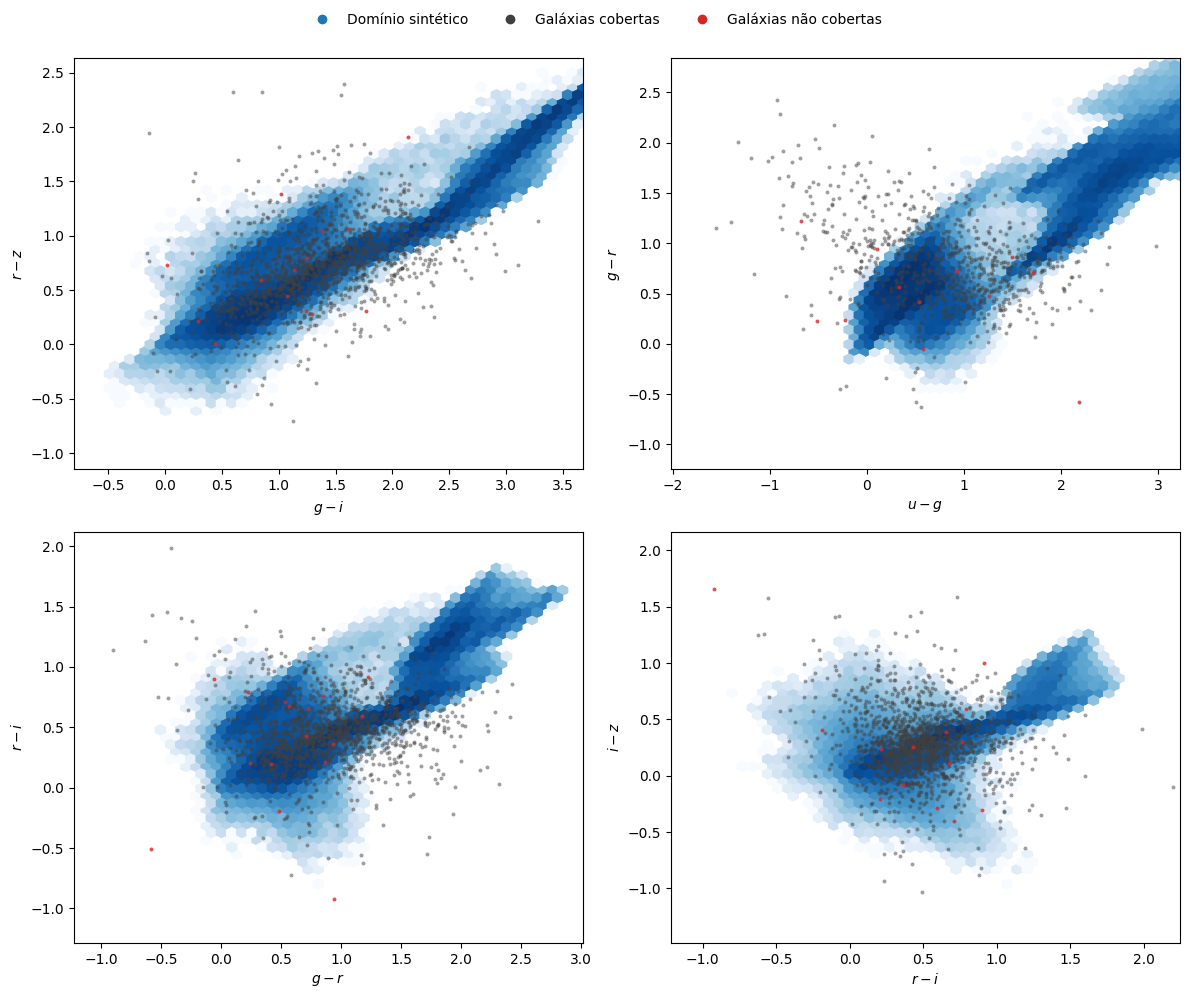

In [6]:
panels = [("g", "i", "r", "z"), ("u", "g", "g", "r"), ("g", "r", "r", "i"), ("r", "i", "i", "z")]
filt_of = dict(zip(BANDS, filt_names))
covered = splus["covered"].to_numpy()
show = np.random.default_rng(SEED).random(len(splus)) < 1500 / len(splus)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (a, b, c, d) in zip(axes.flat, panels):
    ok = show & detected[:, [BANDS.index(k) for k in (a, b, c, d)]].all(1)
    x = (splus[f"{a}_auto"] - splus[f"{b}_auto"])[ok]
    y = (splus[f"{c}_auto"] - splus[f"{d}_auto"])[ok]
    xlim = np.percentile(x, [0.5, 99.5]) + [-0.8, 0.8]
    ylim = np.percentile(y, [0.5, 99.5]) + [-0.8, 0.8]
    ax.hexbin(models[filt_of[a]] - models[filt_of[b]], models[filt_of[c]] - models[filt_of[d]],
              gridsize=50, extent=(*xlim, *ylim), bins="log", mincnt=1, cmap="Blues")
    ax.scatter(x[covered[ok]], y[covered[ok]], s=8, c="0.25", alpha=0.5, lw=0)
    ax.scatter(x[~covered[ok]], y[~covered[ok]], s=8, c="tab:red", alpha=0.8, lw=0)
    ax.set(xlim=xlim, ylim=ylim, xlabel=f"${a} - {b}$", ylabel=f"${c} - {d}$")

legend_labels = {"tab:blue": "Domínio sintético", "0.25": "Galáxias cobertas", "tab:red": "Galáxias não cobertas"}
handles = [plt.Line2D([], [], ls="", marker="o", color=col, label=lab) for col, lab in legend_labels.items()]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

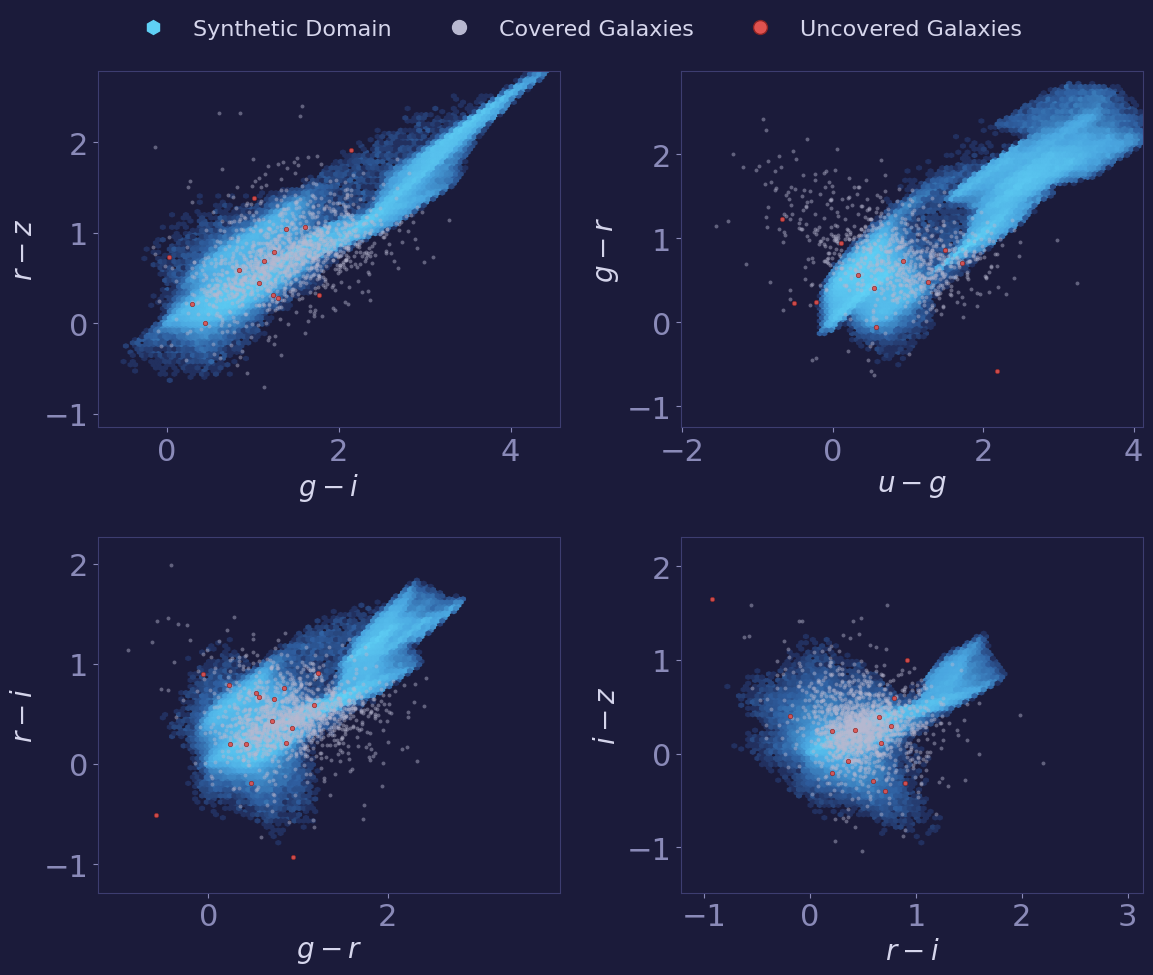

In [12]:
from matplotlib.colors import LinearSegmentedColormap

# --- paleta do pôster (aproximada da imagem; troque pelos hex exatos se tiver) ---
POSTER = {
    "bg": "#12122b",       # fundo do pôster
    "panel": "#1b1b3a",    # caixas das figuras
    "grid": "#2a2a52",     # grade de fundo
    "edge": "#3d3d70",     # bordas
    "text": "#d6d6ec",     # texto
    "muted": "#8a8ab8",    # legendas "Figure N"
    "cyan": "#5fd0f5",     # títulos
    "red": "#e0524f",      # bloco vermelho do tetris
    "red_edge": "#8c2424",
}
domain_cmap = LinearSegmentedColormap.from_list(
    "poster_blue", ["#22305f", "#2f5fa0", "#4aa6e0", POSTER["cyan"]])

style = {
    "figure.facecolor": POSTER["panel"],
    "axes.facecolor": POSTER["panel"],
    "axes.edgecolor": POSTER["edge"],
    "axes.labelcolor": POSTER["text"],
    "axes.labelsize": 20,
    "xtick.color": POSTER["muted"],
    "ytick.color": POSTER["muted"],
    "text.color": POSTER["text"],
    "font.family": "sans-serif",
    "legend.frameon": False,
}

plt.rcParams.update({'font.size': 22})

panels = [("g", "i", "r", "z"), ("u", "g", "g", "r"), ("g", "r", "r", "i"), ("r", "i", "i", "z")]
filt_of = dict(zip(BANDS, filt_names))
covered = splus["covered"].to_numpy()
show = np.random.default_rng(SEED).random(len(splus)) < 1500 / len(splus)

with plt.rc_context(style):
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for ax, (a, b, c, d) in zip(axes.flat, panels):
        ok = show & detected[:, [BANDS.index(k) for k in (a, b, c, d)]].all(1)
        x = (splus[f"{a}_auto"] - splus[f"{b}_auto"])[ok]
        y = (splus[f"{c}_auto"] - splus[f"{d}_auto"])[ok]
        xlim = np.percentile(x, [0.5, 99.5]) + [-0.8, 1.7]
        ylim = np.percentile(y, [0.5, 99.5]) + [-0.8, 0.95]

        ax.hexbin(models[filt_of[a]] - models[filt_of[b]], models[filt_of[c]] - models[filt_of[d]],
                  extent=(*xlim, *ylim), bins="log", mincnt=1, cmap=domain_cmap, zorder=1)
        ax.scatter(x[covered[ok]], y[covered[ok]], s=8, c="#b8b8d0", alpha=0.45, lw=0, zorder=2)
        ax.scatter(x[~covered[ok]], y[~covered[ok]], s=10, c=POSTER["red"], alpha=0.9,
                   edgecolors=POSTER["red_edge"], lw=0.5, zorder=3)
        ax.set(xlim=xlim, ylim=ylim, xlabel=f"${a} - {b}$", ylabel=f"${c} - {d}$")

    handles = [
        plt.Line2D([], [], ls="", marker="h", ms=10, color=POSTER["cyan"], label="Synthetic Domain"),
        plt.Line2D([], [], ls="", marker="o", ms=10, color="#b8b8d0", label="Covered Galaxies"),
        plt.Line2D([], [], ls="", marker="o", ms=10, color=POSTER["red"], mec=POSTER["red_edge"],
                   label="Uncovered Galaxies"),
    ]
    fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=16, labelcolor=POSTER["text"])
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig("color_color.png", dpi=300, facecolor=fig.get_facecolor())
    plt.show()

['uJAVA', 'F0378', 'F0395', 'F0410', 'F0430', 'gSDSS', 'F0515', 'rSDSS', 'F0660', 'iSDSS', 'F0861', 'zSDSS']


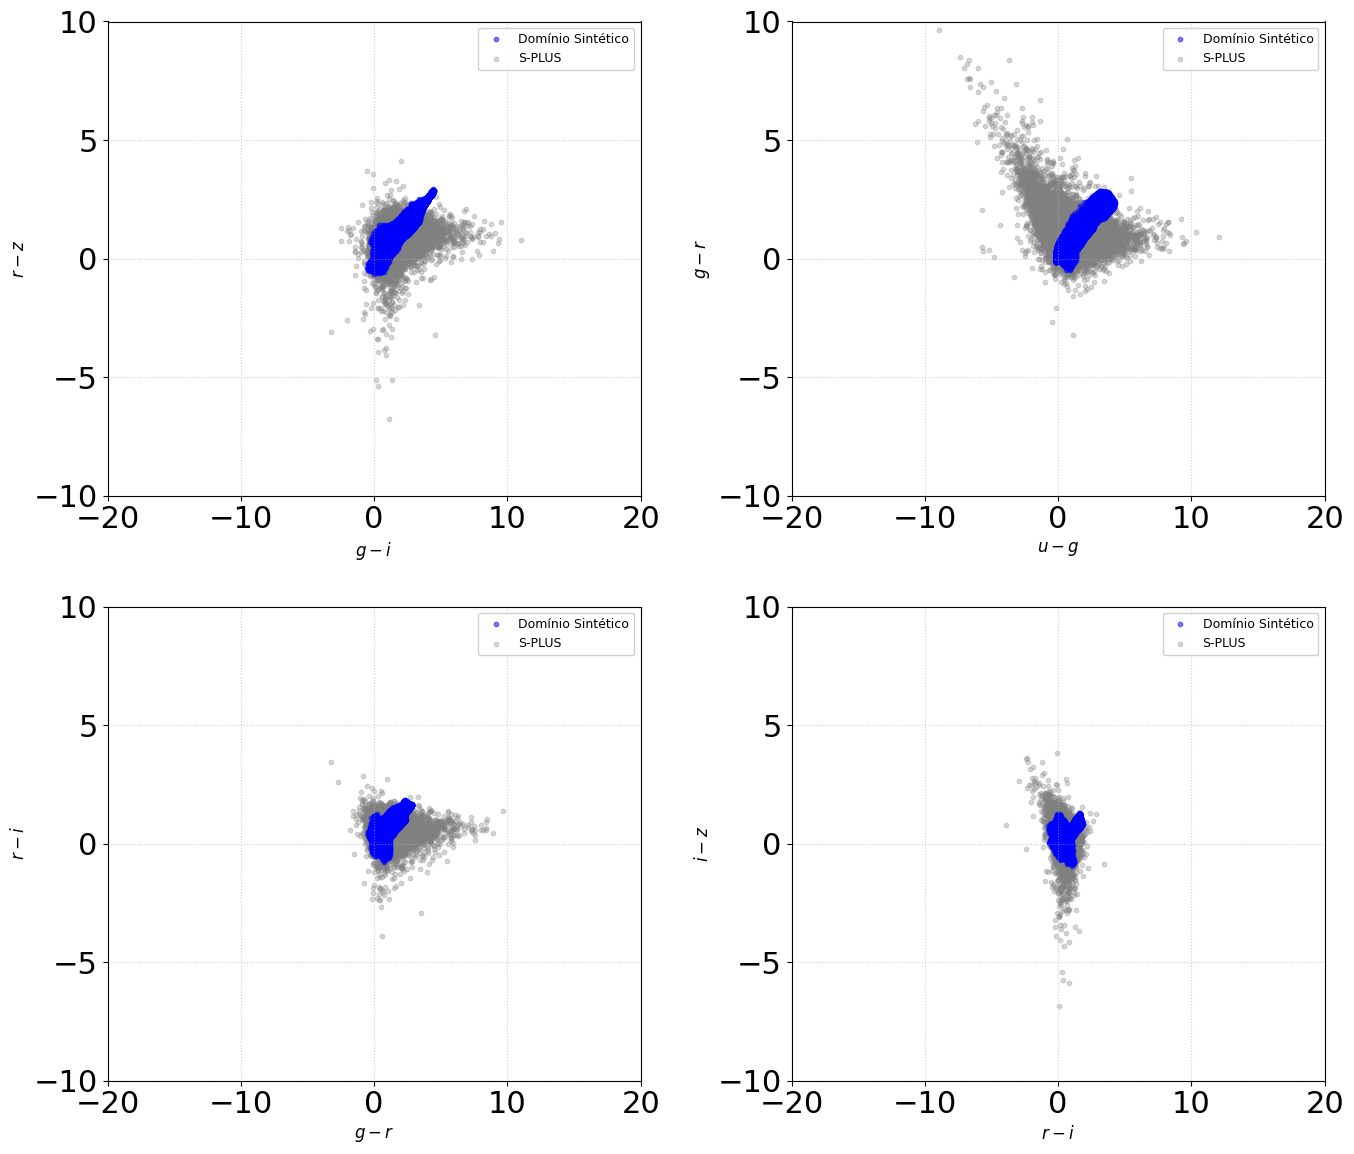

In [8]:
from scipy.spatial import ConvexHull
from matplotlib.lines import Line2D

plt.rcParams["text.usetex"] = False

model_grid = np.loadtxt("training_set.csv", delimiter=",", skiprows=1)
filt_splus_list = [filter.split("/")[1].split(".")[0] for filter in np.loadtxt("splus-filters/splus_filters.txt", dtype="str")]

print(filt_splus_list)

plot_configs = [
    {'x': ('gSDSS', 'iSDSS'), 'y': ('rSDSS', 'zSDSS'), 'xlab': '$g - i$', 'ylab': '$r - z$'},
    {'x': ('uJAVA', 'gSDSS'),  'y': ('gSDSS', 'rSDSS'), 'xlab': '$u - g$', 'ylab': '$g - r$'},
    {'x': ('gSDSS', 'rSDSS'), 'y': ('rSDSS', 'iSDSS'), 'xlab': '$g - r$', 'ylab': '$r - i$'},
    {'x': ('rSDSS', 'iSDSS'), 'y': ('iSDSS', 'zSDSS'), 'xlab': '$r - i$', 'ylab': '$i - z$'}
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

cmap = plt.get_cmap('jet')

# Loop sobre cada subplot e sua configuração de cor
for ax_idx, (ax, config) in enumerate(zip(axes, plot_configs)):
    
    b1_x, b2_x = config['x']
    b1_y, b2_y = config['y']
    
    all_x, all_y = [], []

    ax.scatter(model_grid[:, filt_splus_list.index(b1_x) + 12] - model_grid[:, filt_splus_list.index(b2_x) + 12],
               model_grid[:, filt_splus_list.index(b1_y) + 12] - model_grid[:, filt_splus_list.index(b2_y) + 12],
               c='blue', s=10, alpha=0.5, label='Domínio Sintético', zorder=1)

    splus_data_x = splus[b1_x[0] + '_auto'] - splus[b2_x[0] + '_auto']
    splus_data_y = splus[b1_y[0] + '_auto'] - splus[b2_y[0] + '_auto']

    ax.scatter(splus_data_x, splus_data_y, color='gray', alpha=0.3, s=10, zorder=0, label="S-PLUS") # Dados S-PLUS
    
    # Estilização de cada subplot
    ax.set_xlabel(config['xlab'], fontsize=12)
    ax.set_ylabel(config['ylab'], fontsize=12)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_xlim([-20, 20])
    ax.set_ylim([-10, 10])

    ax.legend(loc='best', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()